# Simple model: baselines, then logistic regression on simple image features

This notebook asks one question: **do features that say nothing about what is drawn (brightness, amount of ink, color) predict map scale any better than guessing?**

It has two parts:
1. **Baselines (section 3):** two models that never look at the image - always predict the majority class, and guess at random in proportion to the real class mix. They set the bar every other model has to clear.
2. **Simple-feature logistic regression (sections 4-8):** image -> simple feature vector -> standardize -> one linear layer -> softmax -> Small / Medium / Large. No hidden layers, no CNN, no HOG/LBP.

How the logistic regression is set up:

| Decision | Choice | Why |
|---|---|---|
| Feature | best of 5 on val: `pixels_32`, `hist_norm`, `ink`, `color`, `combo` | Highest validation macro-F1 |
| Class weighting | none or `balanced`, chosen on val | `2-augment` makes the three classes equal, so `balanced` gives every row weight 1 and matches no weighting; both stay in the search in case the augmentation settings change |
| C (regularization) | 13 values from 1e-6 to 100, chosen on val | Controls over/underfitting; picked by val macro-F1 |
| Training rows | all (original + rescan + augmented) | Without class weighting, training on originals only collapses to always predicting Large |
| Metrics | macro-F1 for all tuning; macro MAE reported alongside | Macro MAE also counts how far off a mistake is (Small called Large = 2 steps), see section 3 |

Sections: 1 settings, 2 data, 3 baselines, 4 features, 5 look at the features, 6 tuning (val), 7 final model, 8 test and comparison to the baselines, 9 save results

## 1. Settings and imports

Ignored the warnings for Pillow's size limit and sklearn's convergence warning. 

For the feature settings, I set thumbnail sizes, the number of hist bins, the ink grid size, and the list of C values to test. 

In [1]:
import hashlib
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage.filters import threshold_otsu

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

Image.MAX_IMAGE_PIXELS = None # A few fold-out maps are huge, so turn off the size guard

warnings.filterwarnings("ignore") # Some of the bigger C values don't fully converge

In [2]:
# ---- Paths ----
# The repo root is the first folder that has a .git folder in it.
ROOT = None
for folder in [Path.cwd()] + list(Path.cwd().parents): #src: https://stackoverflow.com/questions/973473/getting-a-list-of-all-subdirectories-in-the-current-directory
    if (folder / ".git").exists():
        ROOT = folder
        break

PROC = ROOT / "data" / "processed"   # images + manifest.csv from preprocessing
RESULTS_DIR = ROOT / "data" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ---- Feature settings ----
# Thumbnail sizes as (width, height). Processed images are 672 x 1024, so these keep the shape.
THUMB_SIZES = [(32, 48)] #can add more if we want to test

HIST_BINS = 32

INK_GRID_ROWS = 6  # ink density is measured in a 6 x 4 grid of cells
INK_GRID_COLS = 4

COLOR_BINS = 16

COLOR_THUMB_SIZE = (168, 256) # color doesn't need full resolution

# Contrast stretch: these percentiles of each image become 0 (ink) and 1 (paper)
STRETCH_LOW = 1
STRETCH_HIGH = 99


# ---- Model settings ----
# C = how much we let the model fit the training data. Small C = simpler model.
C_GRID = np.logspace(-6, 2, 13) # 13 values from 0.000001 to 100
MAX_ITER = 3000
SEED = 281

CLASS_WEIGHTS = [None, "balanced"]  # both tried in the val search; "balanced" weights rows by 1 / class frequency


# ---- Baseline settings ----
N_GUESS_SEEDS = 1000  # random-guessing baseline: macro-F1 averaged over this many random runs
N_BOOTSTRAP = 1000    # resamples for the confidence interval on the final test macro-F1

CLASS_NAMES = ["Small", "Medium", "Large"]  # labels 0, 1, 2

## 2. Load the data

Labels and splits come from manifest.csv (see the README). The train split has three kinds of rows:
- original: the kept scan of each map
- rescan: another library's scan of the same map
- augmented: a synthetic copy (flipped, slightly tilted, etc.)

Val and test have exactly one scan per map.

I read manifest.csv, split into train/val/test, then pull out the labels and count how many of each I have. I also wanted to double check there is no leakage between the sets. 

In [3]:
# Read manifest.csv and split into train/val/test
manifest = pd.read_csv(PROC / "manifest.csv", keep_default_na=False)

splits = {}
for split_name in ["train", "val", "test"]:
    rows = manifest[manifest["split"] == split_name]
    splits[split_name] = rows.reset_index(drop=True)

# the labels for each split, as numpy arrays
y = {}
for split_name in splits:
    y[split_name] = splits[split_name]["label"].to_numpy()

for split_name in splits:
    counts = np.bincount(y[split_name], minlength=3)
    print(split_name, "->  Small:", counts[0], "  Medium:", counts[1], "  Large:", counts[2], "  total:", counts.sum())

# Split fingerprint: the same function as 1-preprocessing. Same 10 characters = same split as your teammates'.
def split_fingerprint(frame):
    cols = ["image_id", "split", "variant", "label", "source_id"]
    rows = frame.loc[frame["variant"].isin(["original", "rescan"]), cols].astype(str)
    rows = rows.sort_values("image_id").reset_index(drop=True)
    return hashlib.sha1(rows.to_csv(index=False, lineterminator="\n").encode()).hexdigest()[:10]


PREPROCESS = json.loads((PROC / "preprocess_config.json").read_text())
SPLIT_FINGERPRINT = split_fingerprint(manifest)
assert SPLIT_FINGERPRINT == PREPROCESS.get("split_fingerprint", SPLIT_FINGERPRINT), \
    "manifest.csv doesn't match the last 1-preprocessing run - re-run 1-preprocessing and 2-augment"
print("Split fingerprint:", SPLIT_FINGERPRINT)

train ->  Small: 1667   Medium: 1667   Large: 1667   total: 5001
val ->  Small: 26   Medium: 53   Large: 213   total: 292
test ->  Small: 25   Medium: 53   Large: 212   total: 290
Split fingerprint: 430526cf49


In [4]:
# Leakage check. The same map (source_id) or split group (group_id) can't show up in two different splits.
for column in ["source_id", "group_id"]:
    train_ids = set(splits["train"][column])
    val_ids = set(splits["val"][column])
    test_ids = set(splits["test"][column])

    overlap = len(train_ids & val_ids) + len(train_ids & test_ids) + len(val_ids & test_ids)
    print(column, "shared between splits:", overlap)
    assert overlap == 0, "Leakage between splits - re-run 1-preprocessing.ipynb"

source_id shared between splits: 0
group_id shared between splits: 0


## 3. Baselines (no features)

Two models that never look at the image. Every model in this project has to beat them on **macro-F1**: the F1 score of each class, averaged with equal weight. Plain accuracy is misleading here, because about 73% of val/test maps are Large.

Both baselines learn only the class mix, and they learn it from **one row per train map** (`variant == "original"`), because that is the real mix (about 9% Small, 18% Medium, 73% Large). The full train split is rebalanced by rescans and augmentation to equal class counts (about 1,667 rows each), so a baseline fit on it would learn the wrong mix. With a three-way tie, `DummyClassifier` takes the first class, so a "most frequent" model fit on all train rows would predict Small, not Large.

- **Majority class:** always predicts Large.
- **Random guessing:** picks each class at random, in proportion to the real class mix. Its macro-F1 changes from run to run, so we average it over many random seeds and report the range that 95% of runs fall in. Guessing in proportion to the class mix gives the highest expected macro-F1 of any random guesser, about 1/3.

Neither has anything to tune, so scoring them on test does not spend the test set.

**Macro MAE** is a second score that cares about *how wrong* a prediction is. The classes are ordered (Small = 0, Medium = 1, Large = 2), so |predicted - true| counts how many steps off a prediction is: calling a Small map Medium is 1 step off, calling it Large is 2. Macro-F1 counts both as one mistake. Macro MAE averages the steps within each true class, then averages the three classes, so Small counts as much as Large (the same idea as macro-F1). 0 = perfect, and **lower is better**. Always predicting Large scores exactly 1.0 (Small maps are 2 steps off, Medium maps 1, Large maps 0), and random guessing at the class mix averages about 0.94. Tuning below still uses macro-F1 only; macro MAE is reported next to it.

Using sklearn's DummyClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

In [5]:
# Macro MAE: how many steps off a prediction is (Small = 0, Medium = 1, Large = 2), averaged within each
# true class and then over the classes, so Small counts as much as Large. 0 = perfect, lower is better.
def macro_mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    steps_off = np.abs(np.asarray(y_pred) - y_true)
    per_class = []
    for class_id in [0, 1, 2]:
        rows = y_true == class_id
        if rows.any():
            per_class.append(steps_off[rows].mean())
    return float(np.mean(per_class))


# Helper function to get the accuracy, balanced accuracy, macro-F1 and macro MAE
def get_scores(y_true, y_pred):
    scores = {}
    scores["accuracy"] = accuracy_score(y_true, y_pred)
    scores["balanced_acc"] = balanced_accuracy_score(y_true, y_pred)  # average recall per class
    scores["macro_f1"] = f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)
    scores["macro_mae"] = macro_mae(y_true, y_pred)  # lower is better
    return scores


# DummyClassifier ignores the features, so a column of zeros stands in for them.
# That lets the baselines run before the (slow) feature computation.
def no_features(split_name):
    return np.zeros((len(y[split_name]), 1))


# One row per train map = the real class mix
train_originals = (splits["train"]["variant"] == "original").to_numpy()
y_train_maps = y["train"][train_originals]
X_train_maps = np.zeros((len(y_train_maps), 1))

In [6]:
# ---- Majority class: always predict the most common class ----
majority = DummyClassifier(strategy="most_frequent")
majority.fit(X_train_maps, y_train_maps)

majority_class = majority.classes_[majority.class_prior_.argmax()]
print("Class mix of train maps (Small, Medium, Large):", majority.class_prior_.round(3))
print("Majority class:", CLASS_NAMES[majority_class])
assert CLASS_NAMES[majority_class] == "Large", "Expected Large to be the majority class"

baseline_rows = []
majority_pred = {}
for split_name in ["val", "test"]:
    majority_pred[split_name] = majority.predict(no_features(split_name))
    row = {"model": "majority_class", "split": split_name}
    row.update(get_scores(y[split_name], majority_pred[split_name]))
    baseline_rows.append(row)

Class mix of train maps (Small, Medium, Large): [0.087 0.183 0.73 ]
Majority class: Large


In [7]:
# ---- Random guessing in proportion to the real class mix ----
# One run is noisy (val and test have only about 25 Small maps each), so repeat it with many seeds.
guess_f1 = {}
for split_name in ["val", "test"]:
    runs = []
    for seed in range(N_GUESS_SEEDS):
        guesser = DummyClassifier(strategy="stratified", random_state=seed)
        guesser.fit(X_train_maps, y_train_maps)
        runs.append(get_scores(y[split_name], guesser.predict(no_features(split_name))))
    runs = pd.DataFrame(runs)
    guess_f1[split_name] = runs["macro_f1"].to_numpy()

    row = {"model": "random_guess (mean)", "split": split_name}
    row.update(runs.mean().to_dict())
    row["macro_f1_low"] = np.percentile(guess_f1[split_name], 2.5)    # 95% of random runs score
    row["macro_f1_high"] = np.percentile(guess_f1[split_name], 97.5)  # between low and high
    baseline_rows.append(row)

baseline_table = pd.DataFrame(baseline_rows)


def baseline_value(model, split_name, column="macro_f1"):
    match = baseline_table[(baseline_table["model"] == model) & (baseline_table["split"] == split_name)]
    return match[column].item()


# The bars every trained model is compared against below
majority_val_f1 = baseline_value("majority_class", "val")
majority_test_f1 = baseline_value("majority_class", "test")
chance_val_f1 = baseline_value("random_guess (mean)", "val")  # "chance" in the plots and tables below
chance_test_f1 = baseline_value("random_guess (mean)", "test")
chance_test_range = (baseline_value("random_guess (mean)", "test", "macro_f1_low"),
                     baseline_value("random_guess (mean)", "test", "macro_f1_high"))

# The same bars for macro MAE (lower is better)
majority_test_mae = baseline_value("majority_class", "test", "macro_mae")
chance_test_mae = baseline_value("random_guess (mean)", "test", "macro_mae")

baseline_table.round(3)

,model,split,accuracy,balanced_acc,macro_f1,macro_mae,macro_f1_low,macro_f1_high
0,majority_class,val,0.729,0.333,0.281,1.000,NaN,NaN
1,majority_class,test,0.731,0.333,0.282,1.000,NaN,NaN
2,random_guess (mean),val,0.573,0.333,0.332,0.940,0.278,0.391
3,random_guess (mean),test,0.574,0.333,0.332,0.941,0.279,0.389


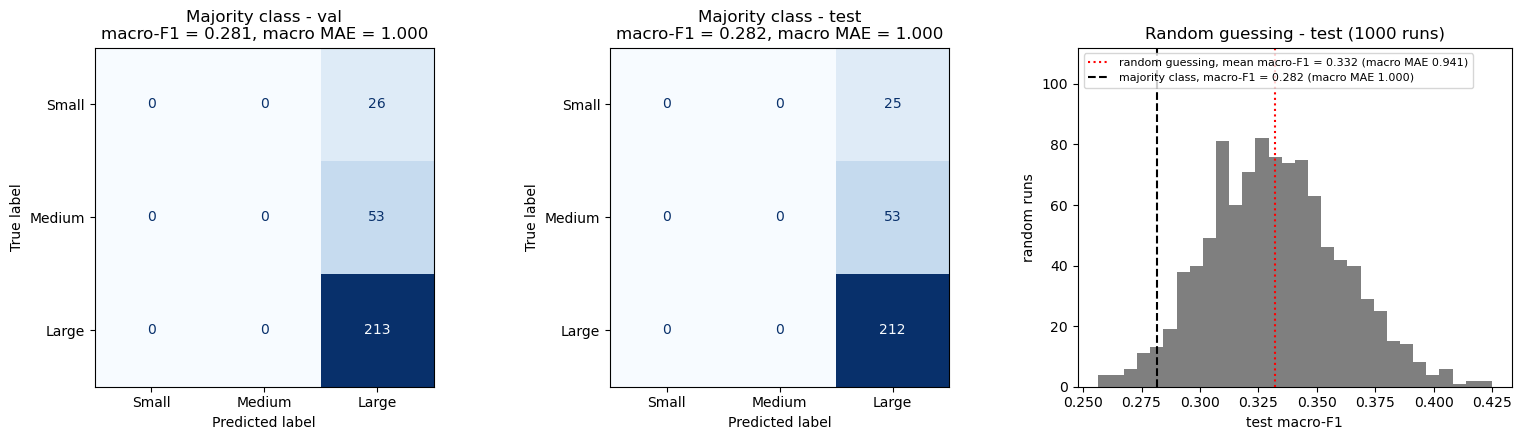

In [8]:
# Left two: confusion matrices for the majority class. Every map lands in the Large column,
# so Small and Medium get F1 = 0 and macro-F1 is just Large's F1 divided by 3.
# Macro MAE is exactly 1.0: Small maps are 2 steps off, Medium maps 1, Large maps 0.
# Right: how much random guessing's test macro-F1 varies from run to run.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, split_name in zip(axes[:2], ["val", "test"]):
    counts = confusion_matrix(y[split_name], majority_pred[split_name], labels=[0, 1, 2])
    ConfusionMatrixDisplay(counts, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Majority class - {split_name}\nmacro-F1 = {baseline_value('majority_class', split_name):.3f}, "
                 f"macro MAE = {baseline_value('majority_class', split_name, 'macro_mae'):.3f}")

ax = axes[2]
ax.hist(guess_f1["test"], bins=30, color="tab:gray")
ax.axvline(chance_test_f1, color="red", linestyle=":", label=f"random guessing, mean macro-F1 = {chance_test_f1:.3f} (macro MAE {chance_test_mae:.3f})")
ax.axvline(majority_test_f1, color="black", linestyle="--", label=f"majority class, macro-F1 = {majority_test_f1:.3f} (macro MAE {majority_test_mae:.3f})")
ax.set_xlabel("test macro-F1")
ax.set_ylabel("random runs")
ax.set_title(f"Random guessing - test ({N_GUESS_SEEDS} runs)")
ax.set_ylim(0, ax.get_ylim()[1] * 1.3)  # headroom so the legend sits above the bars
ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

Always predicting Large gets about 73% accuracy but only about 0.28 macro-F1, because Small and Medium score 0. Random guessing at the real class mix averages about 0.33, with a wide spread from run to run because val and test are small.

On macro MAE (lower is better), always predicting Large scores exactly 1.0 and random guessing about 0.94, so a useful model should land clearly below 0.94.

So a model needs a test macro-F1 clearly **above the random-guessing range** to show that its features carry information about scale. Its accuracy will usually land below the majority class's, because a model trained on the rebalanced train set predicts Small and Medium far more often than they occur.

# Part 2: logistic regression on simple features

Sections 4-5 build the features and look at them, section 6 tunes on val, and sections 7-8 fit the final model and score it on test against the baselines from section 3.

## 4. Features

All of these are simple features that summarize brightness and color. They don't look for edges, shapes or texture.

**Contrast stretch:** Scans differ a lot in paper color (white vs. yellowed) and brightness. Stretching each image so its darkest 1% → 0 and brightest 1% → 1 to standardize.

**Ink:** Otsu's method picks a brightness threshold for each image that best separates dark pixels (ink) from light ones (paper). Source: https://en.wikipedia.org/wiki/Otsu%27s_method 

**Color:** Saturation = how colorful a pixel is. Old paper is a bit yellow, so I subtracted the paper's own saturation (the median, since I think most of the page is paper) and only keep color beyond that.

| Feature | What it is | 
|---|---|
| pixels_32 | The contrast-stretched grayscale image shrunk to 32 × 48 (1,536 numbers) |
| hist_norm | 32-bin brightness histogram of the contrast-stretched image |
| ink | Fraction of ink pixels, overall + in each cell of a 6 × 4 grid |
| color | Saturation beyond the paper's own tint: 16-bin histogram + 3 summary numbers |
| combo | hist_norm + ink + color side by side |

#### Helper Functions ####
- load_rgb: opens a file
- to_gray: converts to grayscale (0-1)
- contrast_stretch: makes each image's darkest 1% black and brightest 1% white (to make yellowed and white paper look alike)
- shrink: makes a thumbnail by averaging blocks of pixels
- fraction_histogram: counts what share of values is in each brightness range

In [9]:
def load_rgb(path):
    # open an image and return an array of shape (height, width, 3) with values 0-255
    with Image.open(path) as img:
        rgb = np.asarray(img.convert("RGB")) #src : https://www.pluralsight.com/resources/blog/guides/importing-image-data-into-numpy-arrays
    return rgb


def to_gray(rgb):
    # grayscale, from 0.0 (black) to 1.0 (white)
    gray_img = Image.fromarray(rgb).convert("L") #src: https://stackoverflow.com/questions/12201577/how-can-i-convert-an-rgb-image-into-grayscale-in-python
    return np.asarray(gray_img, dtype=np.float32) / 255.0


def contrast_stretch(gray):
    low = np.percentile(gray, STRETCH_LOW) #src: https://stackoverflow.com/questions/2374640/how-do-i-calculate-percentiles-with-python-numpy
    high = np.percentile(gray, STRETCH_HIGH)

    # a blank image has nothing to stretch, so leave it alone
    if high - low < 0.000001:
        return gray

    stretched = (gray - low) / (high - low) #src: https://stackoverflow.com/questions/42257173/contrast-stretching-in-python-opencv 
    stretched = np.clip(stretched, 0.0, 1.0)
    return stretched


def shrink(gray, size):
    # Shrink to size = (width, height). Image.BOX averages all the pixels that land in each new pixel, so thin lines still count a little instead of vanishing.
    img = Image.fromarray(gray.astype(np.float32), mode="F") 
    small = img.resize(size, Image.BOX) #using BOX since I want the average for every pixel in the block
    return np.asarray(small, dtype=np.float32)


def fraction_histogram(values, n_bins):
    # fraction of values in each of n_bins equal-width bins between 0 and 1 (adds up to 1)
    counts, edges = np.histogram(values, bins=n_bins, range=(0.0, 1.0))
    return counts / counts.sum()

#### Feature Functions ####
 - ink_density: After contrast-stretching, I use Otsu's method to choose a threshold for dark/light for each image. This way we can differentiate between ink and paper. Instead of giving the model every pixel (which could lead to overfitting by memorizing the specific patterns), I divide the map into 24 big boxes (6 rows x 4 cols) and write what fraction of the pixels in each box are ink. I also report the overall percentage across the whole map of ink. 
 - color_features: Measure how colorful pixels are (beyond the paper's color)

In [10]:
def ink_mask(stretched):
    # True wherever the pixel is ink
    threshold = threshold_otsu(stretched)
    return stretched < threshold


def ink_density(stretched):
    mask = ink_mask(stretched)

    values = [mask.mean()]   # overall ink fraction first

    # split the rows and the columns into nearly-equal chunks to make the grid
    row_chunks = np.array_split(np.arange(mask.shape[0]), INK_GRID_ROWS)
    col_chunks = np.array_split(np.arange(mask.shape[1]), INK_GRID_COLS)

    for rows in row_chunks:
        for cols in col_chunks:
            cell = mask[rows[0] : rows[-1] + 1, cols[0] : cols[-1] + 1]
            values.append(cell.mean())

    return np.array(values)   # 1 + 24 = 25 numbers


def extra_saturation(rgb):
    small = Image.fromarray(rgb).resize(COLOR_THUMB_SIZE, Image.BOX)
    hsv = np.asarray(small.convert("HSV"), dtype=np.float32) / 255.0
    saturation = hsv[:, :, 1]

    paper_saturation = np.median(saturation)
    extra = np.clip(saturation - paper_saturation, 0.0, 1.0)
    return extra, saturation, paper_saturation


def color_features(rgb):
    extra, saturation, paper_saturation = extra_saturation(rgb)

    values = list(fraction_histogram(extra, COLOR_BINS))
    values.append(saturation.mean())
    values.append(paper_saturation)
    # fraction of pixels that are clearly colored
    values.append((extra > 0.15).mean())

    return np.array(values)   # 16 + 3 = 19 numbers

#### Computing One Feature ####

one_feature(rgb, name) takes one loaded image and the name of a feature, and returns that feature as a 1-D array of numbers.

- Every feature starts from the grayscale image
- color uses the image as scanned (so do pixels_raw and hist_raw, early experiments that are not in ALL_FEATURES)
- The others use the contrast-stretched image (darkest 1% → black, brightest 1% → white), so differences in paper color and scanner brightness don't drown out the map itself
- combo joins hist_norm, ink and color into one 76-number vector

In [11]:
# Compute one feature for one image, by name.
def one_feature(rgb, name):
    gray = to_gray(rgb)

    if name == "pixels_raw":
        return shrink(gray, (32, 48)).ravel()
    if name == "hist_raw":
        return fraction_histogram(gray, HIST_BINS)
    if name == "color":
        return color_features(rgb)

    # everything below uses the contrast-stretched image
    stretched = contrast_stretch(gray)

    if name == "pixels_32":
        return shrink(stretched, (32, 48)).ravel()
    if name == "hist_norm":
        return fraction_histogram(stretched, HIST_BINS)
    if name == "ink":
        return ink_density(stretched)
    if name == "combo":
        part1 = fraction_histogram(stretched, HIST_BINS)
        part2 = ink_density(stretched)
        part3 = color_features(rgb)
        return np.concatenate([part1, part2, part3])


BASE_FEATURES = ["pixels_32", "hist_norm", "ink", "color"]
ALL_FEATURES = BASE_FEATURES + ["combo"]

#### Computing Features for Every Image ####

For each split (train, val, test), we go through every image:
1. Open the image once.
2. Compute all five features from that one loaded image.
3. Add each feature's numbers to that feature's list.

At the end of each split, each list becomes a 2-D array: one row per image, one column per number in the feature.
The result is stored as X[feature name][split name], e.g. X["ink"]["train"].

In [12]:
# Compute every feature for every image. Takes several minutes.
X = {}
for name in ALL_FEATURES:
    X[name] = {}

for split_name in ["train", "val", "test"]:
    # start with an empty list for each feature
    rows = {}
    for name in ALL_FEATURES:
        rows[name] = []

    for path in splits[split_name]["path"]:
        rgb = load_rgb(PROC / path)
        for name in ALL_FEATURES:
            rows[name].append(one_feature(rgb, name))

    # turn each list of rows into a 2D array
    for name in ALL_FEATURES:
        X[name][split_name] = np.array(rows[name])
    print(split_name, "done")

train done
val done
test done


#### Timing Each Feature (for the Efficiency Section) ####

To compare costs fairly, we time each feature on the same 50 training images. For each feature, the timer covers loading each image and computing that feature; dividing by 50 gives the average time per image.

Cost per image = loading + that feature's computing time. This is the number used in the efficiency-vs-accuracy comparison.

In [13]:
# How long does each feature take per image? Time it on 50 training images.
sample_paths = list(splits["train"]["path"][:50])

sec_per_image = {}
for name in ALL_FEATURES:
    start = time.perf_counter()
    for path in sample_paths:
        rgb = load_rgb(PROC / path)
        one_feature(rgb, name)
    sec_per_image[name] = (time.perf_counter() - start) / len(sample_paths)

for name in ALL_FEATURES:
    print(name, "-", X[name]["train"].shape[1], "numbers,", round(sec_per_image[name] * 1000, 1), "ms per image")

pixels_32 - 1536 numbers, 17.1 ms per image
hist_norm - 32 numbers, 21.5 ms per image
ink - 25 numbers, 22.4 ms per image
color - 19 numbers, 12.4 ms per image
combo - 76 numbers, 32.8 ms per image


## 5. Look at the features

One training map per class, shown four ways. Then class averages, using only one row per map (variant == "original") so augmented copies don't count twice. Not using the augmentations is only for this visualization! I use the augmented copies in the actual model. 

If the classes look the same here, a linear model won't be able to tell them apart either.

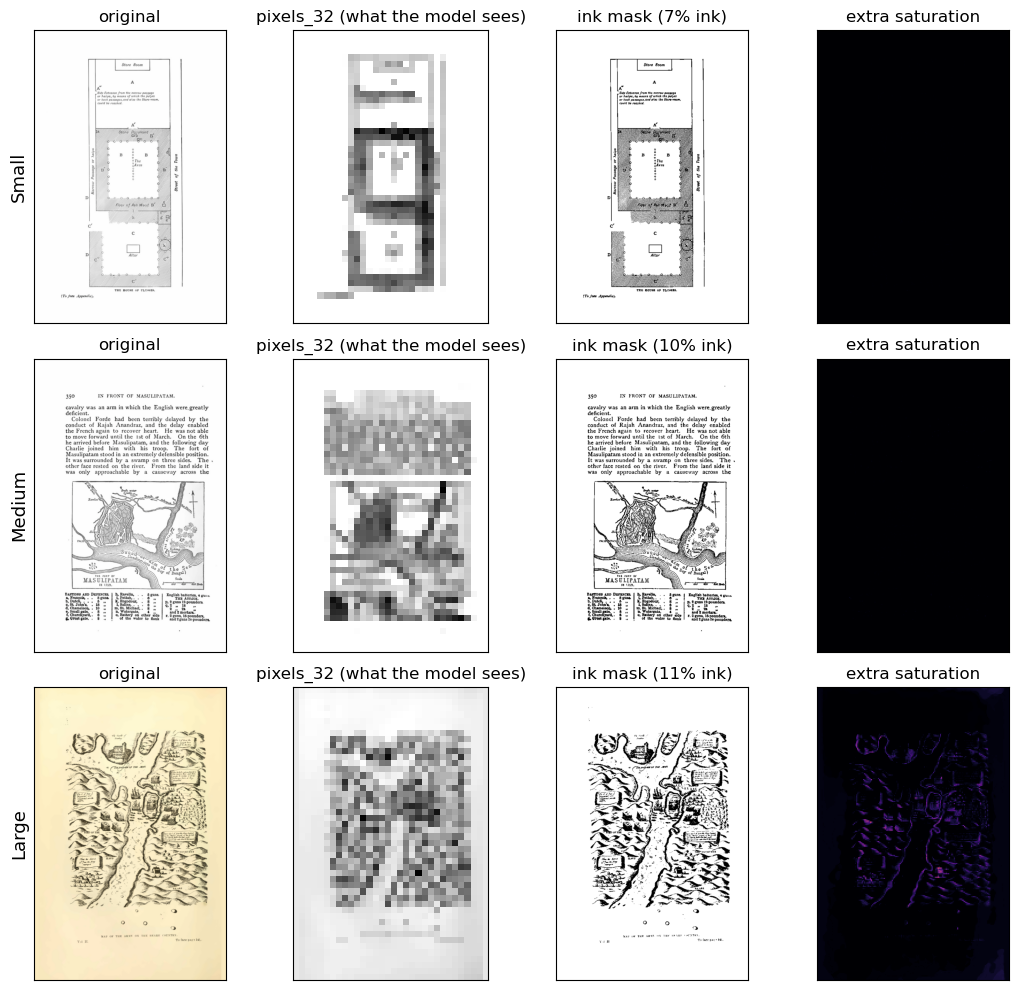

In [14]:
rng = np.random.default_rng(SEED)
train_rows = splits["train"]
is_original = (train_rows["variant"] == "original").to_numpy()

# want an image with 3 rows (1 per class) and 4 cols (1 per feature: original, pixels_32, ink mask, and extra saturation)
fig, axes = plt.subplots(3, 4, figsize=(11, 10))

for class_id in range(3):
    # pick a random original map from this class
    candidates = np.where(is_original & (y["train"] == class_id))[0]
    i = rng.choice(candidates)

    rgb = load_rgb(PROC / train_rows.loc[i, "path"])
    stretched = contrast_stretch(to_gray(rgb))
    mask = ink_mask(stretched)
    extra, saturation, paper_saturation = extra_saturation(rgb)

    axes[class_id, 0].imshow(rgb)
    axes[class_id, 0].set_title("original")

    axes[class_id, 1].imshow(shrink(stretched, (32, 48)), cmap="gray")
    axes[class_id, 1].set_title("pixels_32 (what the model sees)")

    axes[class_id, 2].imshow(mask, cmap="gray_r")
    axes[class_id, 2].set_title(f"ink mask ({mask.mean():.0%} ink)")

    axes[class_id, 3].imshow(extra, cmap="magma", vmin=0, vmax=0.5)
    axes[class_id, 3].set_title("extra saturation")

    for ax in axes[class_id]:
        ax.set_xticks([])
        ax.set_yticks([])
    axes[class_id, 0].set_ylabel(CLASS_NAMES[class_id], fontsize=13)

plt.tight_layout()
plt.show()

#### Look at Class Averages ####

Instead of showing one example, I'm averaging a feature over all the maps in a class. 

For example, it averages the ink fraction of every Small map, then of every Medium map, then of every Large map. If the three classes’ averages look about the same, the feature probably can’t tell them apart.



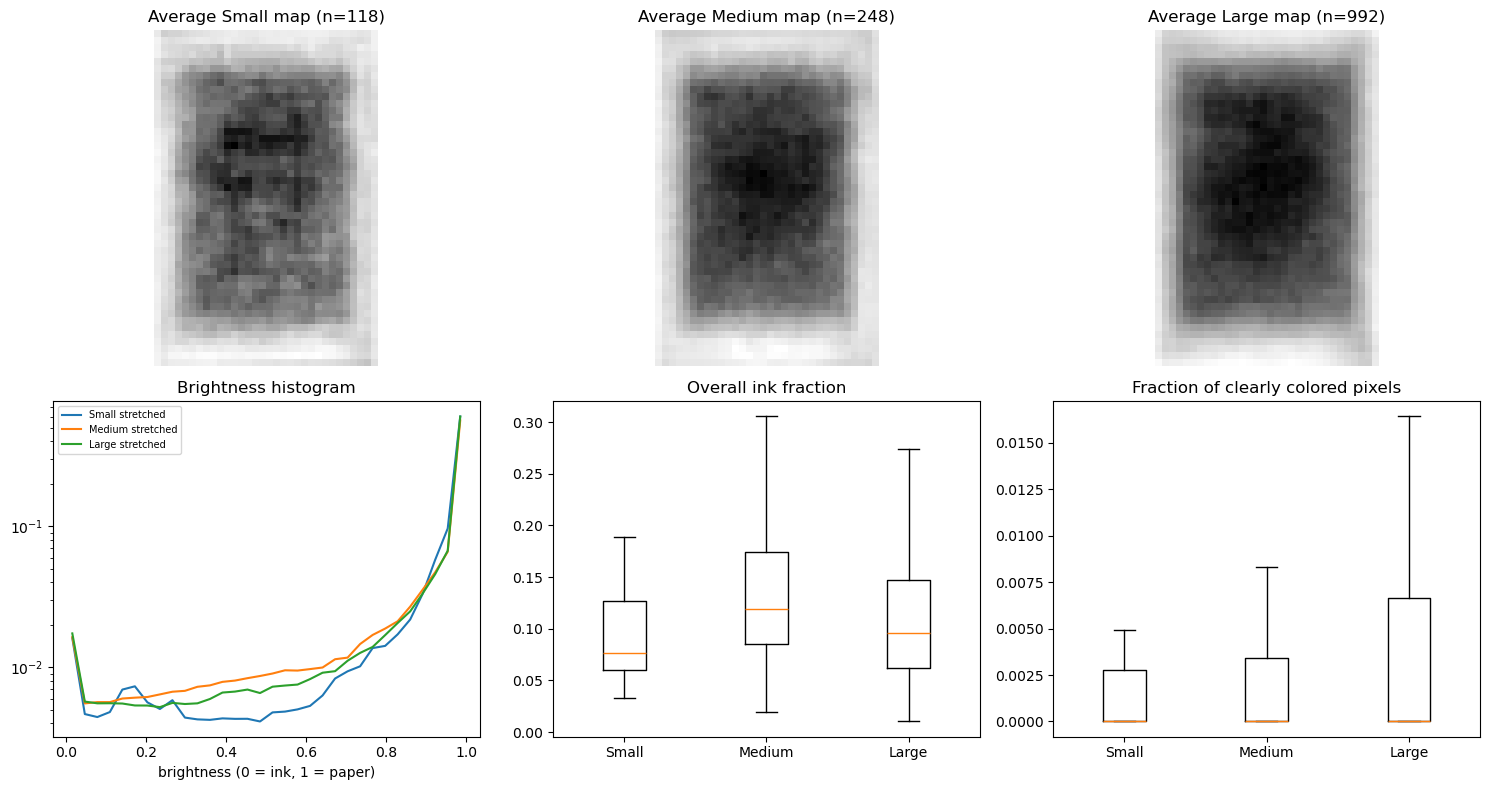

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# --- top row: the average 32 x 48 thumbnail of each class ---
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    mean_thumb = X["pixels_32"]["train"][rows].mean(axis=0)

    axes[0, class_id].imshow(mean_thumb.reshape(48, 32), cmap="gray")
    axes[0, class_id].set_title(f"Average {CLASS_NAMES[class_id]} map (n={rows.sum()})")
    axes[0, class_id].axis("off")


# --- bottom left: brightness histogram before and after the stretch ---
bin_centers = (np.arange(HIST_BINS) + 0.5) / HIST_BINS
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    norm = X["hist_norm"]["train"][rows].mean(axis=0)
    axes[1, 0].plot(bin_centers, norm, label=CLASS_NAMES[class_id] + " stretched")

axes[1, 0].set_yscale("log")
axes[1, 0].set_xlabel("brightness (0 = ink, 1 = paper)")
axes[1, 0].set_title("Brightness histogram")
axes[1, 0].legend(fontsize=7)


# --- bottom middle: overall ink fraction (column 0 of the ink feature) ---
groups = []
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    groups.append(X["ink"]["train"][rows, 0])
axes[1, 1].boxplot(groups, showfliers=False)
axes[1, 1].set_xticks([1, 2, 3], CLASS_NAMES)
axes[1, 1].set_title("Overall ink fraction")


# --- bottom right: fraction of clearly colored pixels (last column of color) ---
groups = []
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    groups.append(X["color"]["train"][rows, -1])
axes[1, 2].boxplot(groups, showfliers=False)
axes[1, 2].set_xticks([1, 2, 3], CLASS_NAMES)
axes[1, 2].set_title("Fraction of clearly colored pixels")

plt.tight_layout()
plt.show()

## 6. Tuning: compare features (validation set only)

Model: Multinomial logistic regression has one weight per feature (plus a bias) for each class. It scores an image as weights · features + bias, and turns the three scores into probabilities with softmax.

C: controls how strongly large weights are penalized. Small C = higher penalty -> simpler model (may underfit). Large C = weaker penalty (may overfit). Source: https://www.kaggle.com/code/usman8/logistic-regression-tuning-the-c-parameter

Class weighting: with `class_weight="balanced"`, each training row counts in proportion to 1 / (its class's share of the train rows), so Small gets as much attention as Medium and Large. `2-augment` now makes the three classes equal, so `"balanced"` gives every row a weight of 1 and scores exactly like `None`. Both stay in the search, so it still works if the augmentation settings change.

For each feature and class weighting, we try every C in C_GRID. Each time: fit on train, score on val. The test set isn't used in this section.

Choosing: we pick the setting (feature, class weighting, C) with the highest validation macro-F1. Picking the best of 130 settings on one val set can be optimistic - the winner's val score is partly luck, so test may come in lower. Any such bias works in the model's favor, which is fine for a baseline.

If a feature's best C is at the bottom of the grid (1e-6), its weights are close to 0 and the model is close to just predicting the class mix. That is a sign the feature carries little information, not that C should go even lower.

This section fits 130 models (5 features x 2 weightings x 13 C values); it can take several minutes, mostly for the big pixel features at large C.

In [16]:
def fit_and_score(X_train, y_train, X_val, y_val, C, class_weight):
    # Scale: every feature gets mean 0 and std 1, using the training data only.
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    model = LogisticRegression(C=C, class_weight=class_weight, max_iter=MAX_ITER, random_state=SEED)
    model.fit(X_train_scaled, y_train)

    train_f1 = f1_score(y_train, model.predict(X_train_scaled), average="macro")
    val_pred = model.predict(X_val_scaled)
    return train_f1, val_pred

def pick_C(results):
    # Pick the C with the highest validation macro-F1
    best = results[0]
    for r in results:
        if r["val_macro_f1"] > best["val_macro_f1"]:
            best = r
    return best

In [17]:
#### Searching C for every feature and class weighting ####

all_rows = []      # every C tried, for the curve plots
summary_rows = []  # one row per (feature, class weighting), at its chosen C

for name in ALL_FEATURES:
    for class_weight in CLASS_WEIGHTS:
        weighting = "balanced" if class_weight == "balanced" else "none"  # label for tables and plots

        # Try every C
        results = []
        for C in C_GRID:
            train_f1, val_pred = fit_and_score(X[name]["train"], y["train"],
                                               X[name]["val"], y["val"], C, class_weight)
            val_f1 = f1_score(y["val"], val_pred, average="macro")
            results.append({"C": C, "train_macro_f1": train_f1, "val_macro_f1": val_f1, "val_pred": val_pred})

        chosen = pick_C(results)

        for r in results:
            all_rows.append({"feature": name, "weighting": weighting, "C": r["C"],
                             "train_macro_f1": r["train_macro_f1"], "val_macro_f1": r["val_macro_f1"]})

        summary_rows.append({"feature": name, "weighting": weighting, "chosen_C": chosen["C"],
                             "val_macro_f1": chosen["val_macro_f1"],
                             "train_macro_f1": chosen["train_macro_f1"],
                             "n_features": X[name]["train"].shape[1],
                             "ms_per_image": sec_per_image[name] * 1000})

        print(name, "|", weighting, "| val macro-F1 =", round(chosen["val_macro_f1"], 3))

curves = pd.DataFrame(all_rows)
feature_table = pd.DataFrame(summary_rows)

pixels_32 | none | val macro-F1 = 0.344
pixels_32 | balanced | val macro-F1 = 0.344
hist_norm | none | val macro-F1 = 0.229
hist_norm | balanced | val macro-F1 = 0.229
ink | none | val macro-F1 = 0.35
ink | balanced | val macro-F1 = 0.35
color | none | val macro-F1 = 0.314
color | balanced | val macro-F1 = 0.314
combo | none | val macro-F1 = 0.339
combo | balanced | val macro-F1 = 0.339


In [18]:
# Compare to the baselines from section 3
feature_table["beats_chance_by"] = feature_table["val_macro_f1"] - chance_val_f1
feature_table["beats_majority_by"] = feature_table["val_macro_f1"] - majority_val_f1
feature_table = feature_table.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)

print(f"Random guessing on val: {chance_val_f1:.3f}   Majority class on val: {majority_val_f1:.3f}")
feature_table.round(4).assign(chosen_C=feature_table["chosen_C"].map("{:.1e}".format))

Random guessing on val: 0.332   Majority class on val: 0.281


,feature,weighting,chosen_C,val_macro_f1,train_macro_f1,n_features,ms_per_image,beats_chance_by,beats_majority_by
0,ink,none,2.2e-03,0.3496,0.4841,25,22.4030,0.0172,0.0684
1,ink,balanced,2.2e-03,0.3496,0.4841,25,22.4030,0.0172,0.0684
2,pixels_32,balanced,2.2e-05,0.3439,0.4857,1536,17.0948,0.0116,0.0627
3,pixels_32,none,2.2e-05,0.3439,0.4857,1536,17.0948,0.0116,0.0627
4,combo,none,2.2e-03,0.3387,0.5163,76,32.8002,0.0064,0.0576
5,combo,balanced,2.2e-03,0.3387,0.5163,76,32.8002,0.0064,0.0576
6,color,balanced,1.0e+00,0.3137,0.3719,19,12.4291,-0.0186,0.0326
7,color,none,1.0e+00,0.3137,0.3719,19,12.4291,-0.0186,0.0326
8,hist_norm,none,1.0e+00,0.2290,0.4409,32,21.5067,-0.1033,-0.0522
9,hist_norm,balanced,1.0e+00,0.2290,0.4409,32,21.5067,-0.1033,-0.0522


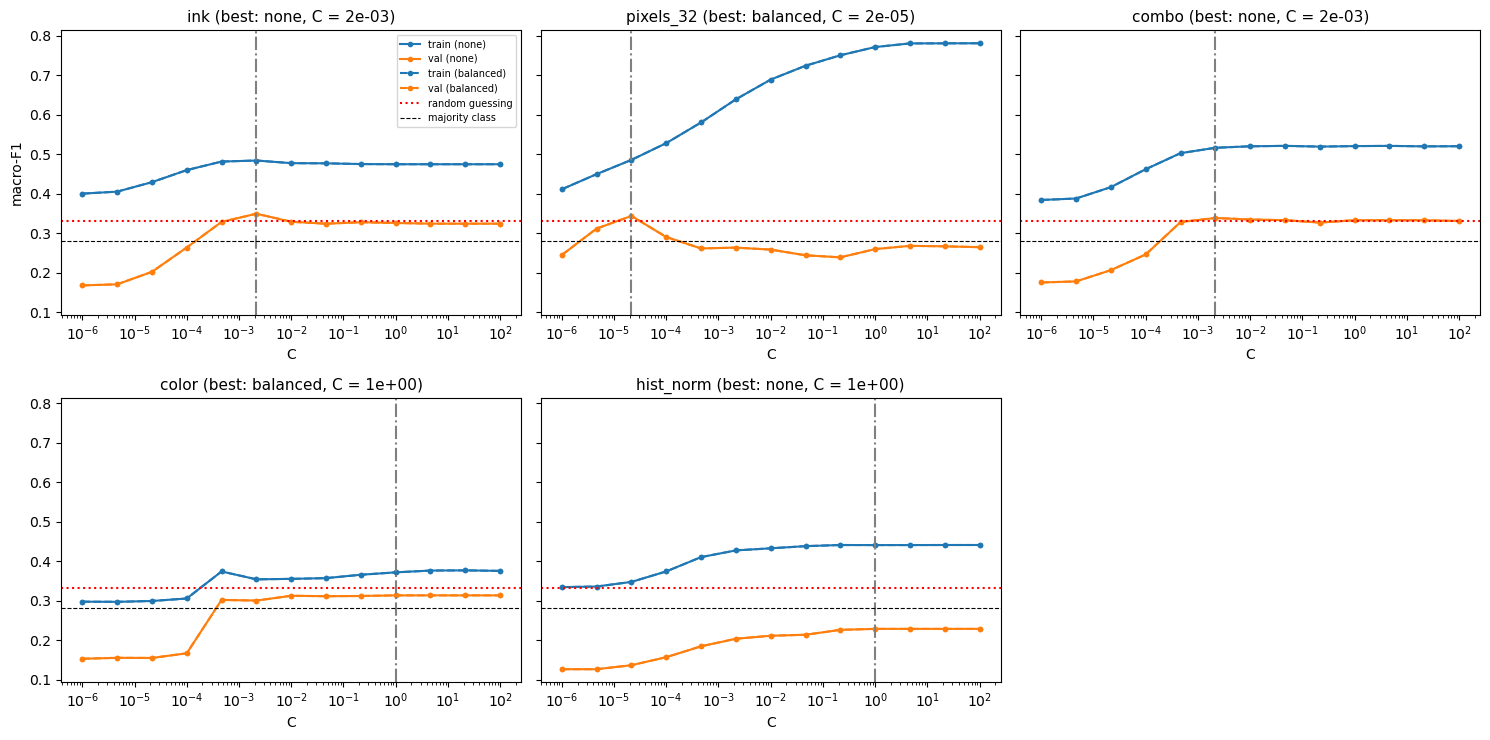

In [19]:
# Train vs. val curves across C, for each feature. Solid = no class weighting, dashed = balanced.
# A big gap between train and val means overfitting. Low, flat lines mean the feature doesn't carry much information.
# Red dotted = random guessing, black dashed = majority class (both on val, from section 3).

plot_features = list(dict.fromkeys(feature_table["feature"]))  # each feature once, best first

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
axes = axes.ravel()

for i, name in enumerate(plot_features):
    ax = axes[i]
    for weighting, style in [("none", "-"), ("balanced", "--")]:
        this_curve = curves[(curves["feature"] == name) & (curves["weighting"] == weighting)]
        ax.plot(this_curve["C"], this_curve["train_macro_f1"], style, color="tab:blue",
                marker="o", markersize=3, label=f"train ({weighting})")
        ax.plot(this_curve["C"], this_curve["val_macro_f1"], style, color="tab:orange",
                marker="o", markersize=3, label=f"val ({weighting})")

    # gray dash-dot line = chosen C for this feature's better weighting
    best = feature_table[feature_table["feature"] == name].iloc[0]
    ax.axvline(best["chosen_C"], color="gray", linestyle="-.")
    ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
    ax.axhline(majority_val_f1, color="black", linestyle="--", linewidth=0.8, label="majority class")

    ax.set_xscale("log")
    ax.set_xlabel("C")
    ax.set_title(f"{name} (best: {best['weighting']}, C = {best['chosen_C']:.0e})", fontsize=11)

# 5 features but 6 spots: hide the empty one
for j in range(len(plot_features), len(axes)):
    axes[j].axis("off")

axes[0].set_ylabel("macro-F1")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 7. Final model

The setting with the highest validation macro-F1 in section 6 (feature, class weighting and C). Its val score is the one it was picked on, so it is optimistic.

Chosen feature: ink   class weighting: none   C: 2.15e-03
Val macro-F1 at that setting: 0.350
Random guessing on val: 0.332   Majority class on val: 0.281


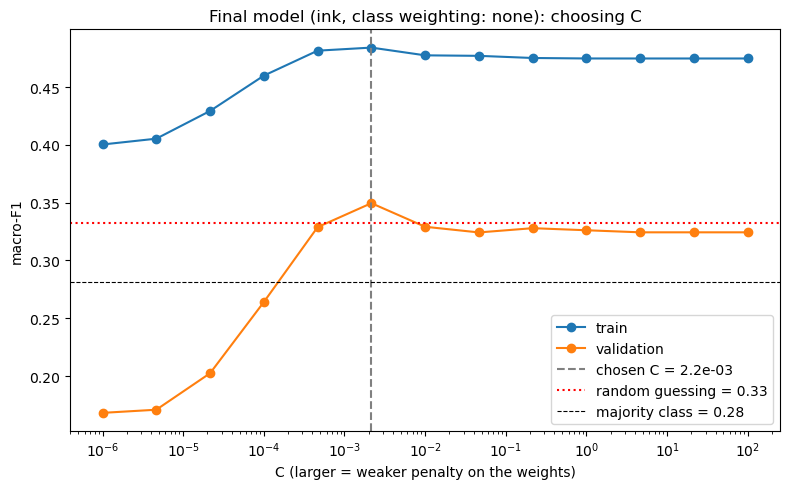

In [20]:
# Chosen in section 6 using the validation set: the top row of feature_table
final_row = feature_table.iloc[0]
FINAL_FEATURE = final_row["feature"]
FINAL_WEIGHTING = final_row["weighting"]
final_class_weight = "balanced" if FINAL_WEIGHTING == "balanced" else None
chosen_C = final_row["chosen_C"]

# Src: DATASCI207
# Scale the features
# StandardScaler shifts and rescales every feature to mean 0 and standard deviation 1, so no feature counts more just because its numbers happen to be bigger.
# It learns the mean and std from the TRAINING data only. If it saw val or test, information about those maps would leak into training.
scaler = StandardScaler()
scaler.fit(X[FINAL_FEATURE]["train"])

# Apply that same training-based scaling to train, val and test
X_scaled = {}
for split_name in splits:
    X_scaled[split_name] = scaler.transform(X[FINAL_FEATURE][split_name])


# This setting's train and val scores at every C we tried (for the plot below)
final_curve = curves[(curves["feature"] == FINAL_FEATURE) & (curves["weighting"] == FINAL_WEIGHTING)]


#Print a quick summary
print(f"Chosen feature: {FINAL_FEATURE}   class weighting: {FINAL_WEIGHTING}   C: {chosen_C:.2e}")
print(f"Val macro-F1 at that setting: {final_row['val_macro_f1']:.3f}")
print(f"Random guessing on val: {chance_val_f1:.3f}   Majority class on val: {majority_val_f1:.3f}")

# Plot: how the chosen setting's train and val scores change with C
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(final_curve["C"], final_curve["train_macro_f1"], marker="o", label="train")
ax.plot(final_curve["C"], final_curve["val_macro_f1"], marker="o", label="validation")

# Gray dashed line = the C we chose. Red dotted = random guessing. Black dashed = majority class.
ax.axvline(chosen_C, color="gray", linestyle="--", label=f"chosen C = {chosen_C:.1e}")
ax.axhline(chance_val_f1, color="red", linestyle=":", label=f"random guessing = {chance_val_f1:.2f}")
ax.axhline(majority_val_f1, color="black", linestyle="--", linewidth=0.8, label=f"majority class = {majority_val_f1:.2f}")

# C goes from 0.000001 to 100, so a log scale spaces the values out evenly
ax.set_xscale("log")
ax.set_xlabel("C (larger = weaker penalty on the weights)")
ax.set_ylabel("macro-F1")
ax.set_title(f"Final model ({FINAL_FEATURE}, class weighting: {FINAL_WEIGHTING}): choosing C")
ax.legend()

plt.tight_layout()
plt.show()

## 8. Test set (run once)

Refit with the chosen setting (feature, class weighting, C) on train, then score test. Don't go back and change anything above after seeing these numbers, or the test score stops being an honest estimate.

For the efficiency-vs-accuracy section:
- **Training cost** = computing features for every training image + fitting
- **Inference cost per image** = loading + features + predicting, for one image

In [21]:
#Build final model
# max_iter = the most optimization steps it may take before stopping.
final_model = LogisticRegression(C=chosen_C, class_weight=final_class_weight, max_iter=MAX_ITER, random_state=SEED) #using rnadom_state so I get the same results every time
 

# Train it & time the training
t = time.perf_counter() #src: https://stackoverflow.com/questions/66036844/time-time-or-time-perf-counter-which-is-faster?__cf_chl_tk=gGOPjeytMAfl4xANAJdo8XDI5bCN5qs32PLxCSzrZh8-1793660829-1.0.1.1-.1qi8znX5CApK7Su37a6oxXRRQnzljd58A1AJz4lZX8
final_model.fit(X_scaled["train"], y["train"])
fit_seconds = time.perf_counter() - t


# Predict the test set, and time it
t = time.perf_counter()
test_pred = final_model.predict(X_scaled["test"])
predict_seconds = time.perf_counter() - t


#Score the predictions
test_scores = get_scores(y["test"], test_pred)
per_class_f1 = f1_score(y["test"], test_pred, average=None) #gives one F1 per class instead of the average: [Small, Medium, Large]


#Costs, for the efficiency-vs-accuracy section
n_train = len(y["train"])
n_test = len(y["test"])

#Training cost = making features for every training image +fitting the model
train_cost_seconds = sec_per_image[FINAL_FEATURE] * n_train + fit_seconds

# Inference Cost for 1 new image = making its features +its share of the prediction time.
inference_ms = (sec_per_image[FINAL_FEATURE] + predict_seconds / n_test) * 1000 #multiply by 1000 to turn seconds into milliseconds.


# Compare test to chance and to val. If test is much lower than val, the model fit the val set by luck.
print(f"Test macro-F1:     {test_scores['macro_f1']:.3f}   (random guessing: {chance_test_f1:.3f}, majority class: {majority_test_f1:.3f})")
print(f"Test balanced acc: {test_scores['balanced_acc']:.3f}")
print(f"Test accuracy:     {test_scores['accuracy']:.3f}")
print(f"Test macro MAE:    {test_scores['macro_mae']:.3f} steps   (random guessing: {chance_test_mae:.3f}, "
      f"majority class: {majority_test_mae:.3f}; lower is better)")
print(f"Val macro-F1 was:  {final_row['val_macro_f1']:.3f}")
print()

print(f"Training cost:  {train_cost_seconds:.1f} s  (fitting alone: {fit_seconds:.2f} s)")
print(f"Inference cost: {inference_ms:.1f} ms per image")
print()

# Two-step errors are the worst kind: a Small map called Large, or a Large map called Small
two_step_errors = (np.abs(test_pred - y["test"]) == 2).sum()
n_errors = (test_pred != y["test"]).sum()
print(f"Two-step errors (Small called Large, or Large called Small): {two_step_errors} of {n_errors} errors")
print()

# Precision, recall and F1 for each class.
#   precision = of the maps it called Small, how many really were Small
#   recall    = of the real Small maps, how many it found
#   support   = how many test maps are in that class
print(classification_report(y["test"], test_pred, target_names=CLASS_NAMES, digits=3))

Test macro-F1:     0.383   (random guessing: 0.332, majority class: 0.282)
Test balanced acc: 0.467
Test accuracy:     0.434
Test macro MAE:    0.794 steps   (random guessing: 0.941, majority class: 1.000; lower is better)
Val macro-F1 was:  0.350

Training cost:  112.0 s  (fitting alone: 0.01 s)
Inference cost: 22.4 ms per image

Two-step errors (Small called Large, or Large called Small): 91 of 164 errors

              precision    recall  f1-score   support

       Small      0.114     0.480     0.185        25
      Medium      0.365     0.509     0.425        53
       Large      0.784     0.410     0.539       212

    accuracy                          0.434       290
   macro avg      0.421     0.467     0.383       290
weighted avg      0.650     0.434     0.487       290



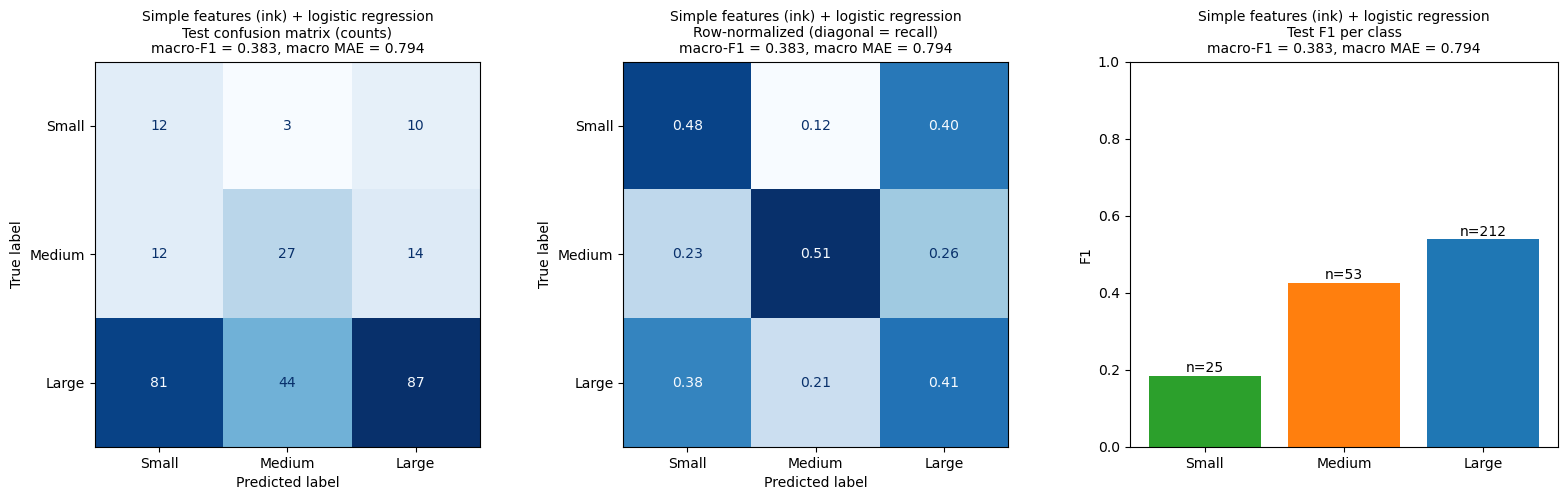

In [22]:
# Confusion Matrix, Src: DATASCI207

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# The model and its scores go in every title, so each panel can be cropped on its own for slides
model_name = f"Simple features ({FINAL_FEATURE}) + logistic regression"
score_line = f"macro-F1 = {test_scores['macro_f1']:.3f}, macro MAE = {test_scores['macro_mae']:.3f}"


counts = confusion_matrix(y["test"], test_pred)
ConfusionMatrixDisplay(counts, display_labels=CLASS_NAMES).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"{model_name}\nTest confusion matrix (counts)\n{score_line}", fontsize=10)

# Each row adds up to 1, so the diagonal is the recall of that class
rates = confusion_matrix(y["test"], test_pred, normalize="true")
ConfusionMatrixDisplay(rates, display_labels=CLASS_NAMES).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title(f"{model_name}\nRow-normalized (diagonal = recall)\n{score_line}", fontsize=10)

class_counts = np.bincount(y["test"], minlength=3)
bars = axes[2].bar(CLASS_NAMES, per_class_f1, color=["tab:green", "tab:orange", "tab:blue"])
for k in range(3):
    bar = bars[k]
    axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"n={class_counts[k]}", ha="center")
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("F1")
axes[2].set_title(f"{model_name}\nTest F1 per class\n{score_line}", fontsize=10)

plt.tight_layout()
plt.show()

### Comparison to the baselines

The question from the top of the notebook: does the model beat guessing? Its test macro-F1 and macro MAE are compared with the two baselines from section 3, and with how often random guessing scores at least that high. The test set is small (about 25 Small maps), so the score is noisy; a bootstrap (re-scoring on test maps resampled with replacement) puts a 95% interval on it. A per-class table then shows which classes any edge comes from.

In [23]:
# Bootstrap: resample the test maps with replacement and re-score, many times
rng = np.random.default_rng(SEED)
boot_f1 = []
boot_mae = []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_test, n_test)
    boot_f1.append(f1_score(y["test"][idx], test_pred[idx], labels=[0, 1, 2], average="macro", zero_division=0))
    boot_mae.append(macro_mae(y["test"][idx], test_pred[idx]))
model_low, model_high = np.percentile(boot_f1, [2.5, 97.5])
mae_low, mae_high = np.percentile(boot_mae, [2.5, 97.5])

# How often does random guessing (section 3) score at least as well as the model?
# The smaller this share, the less likely the model's edge is just luck.
share_as_good = (guess_f1["test"] >= test_scores["macro_f1"]).mean()

comparison = pd.DataFrame([
    {"model": "majority_class",
     "test_macro_f1": majority_test_f1,
     "test_macro_mae": majority_test_mae,
     "test_accuracy": baseline_value("majority_class", "test", "accuracy"),
     "95% range": "-"},
    {"model": "random_guess (mean)",
     "test_macro_f1": chance_test_f1,
     "test_macro_mae": chance_test_mae,
     "test_accuracy": baseline_value("random_guess (mean)", "test", "accuracy"),
     "95% range": f"{chance_test_range[0]:.3f} - {chance_test_range[1]:.3f} (across random runs)"},
    {"model": f"logistic regression ({FINAL_FEATURE}, {FINAL_WEIGHTING})",
     "test_macro_f1": test_scores["macro_f1"],
     "test_macro_mae": test_scores["macro_mae"],
     "test_accuracy": test_scores["accuracy"],
     "95% range": f"{model_low:.3f} - {model_high:.3f} (bootstrap over test maps)"},
])

print(f"Test macro-F1 {test_scores['macro_f1']:.3f}: {share_as_good:.1%} of the {N_GUESS_SEEDS} "
      f"random-guessing runs score at least this high.")
print("Rough guide: over 5% = could easily be luck, 1-5% = borderline, under 1% = clearly better than guessing.")
print(f"Test macro MAE {test_scores['macro_mae']:.3f} steps (bootstrap 95% interval {mae_low:.3f} - {mae_high:.3f}); lower is better.")

comparison.round(3)

Test macro-F1 0.383: 4.6% of the 1000 random-guessing runs score at least this high.
Rough guide: over 5% = could easily be luck, 1-5% = borderline, under 1% = clearly better than guessing.
Test macro MAE 0.794 steps (bootstrap 95% interval 0.658 - 0.932); lower is better.


,model,test_macro_f1,test_macro_mae,test_accuracy,95% range
0,majority_class,0.282,1.000,0.731,-
1,random_guess (mean),0.332,0.941,0.574,0.279 - 0.389 (across random runs)
2,"logistic regression (ink, none)",0.383,0.794,0.434,0.324 - 0.440 (bootstrap over test maps)


In [24]:
# Where does any edge come from? Per-class test F1 for the model vs. the baselines.
# Random guessing is averaged over the same seeds as section 3.
guess_per_class = []
guess_steps = []
for seed in range(N_GUESS_SEEDS):
    guesser = DummyClassifier(strategy="stratified", random_state=seed)
    guesser.fit(X_train_maps, y_train_maps)
    guess_pred = guesser.predict(no_features("test"))
    guess_per_class.append(f1_score(y["test"], guess_pred, labels=[0, 1, 2], average=None, zero_division=0))
    guess_steps.append([np.abs(guess_pred[y["test"] == c] - c).mean() for c in [0, 1, 2]])

# Average steps off for the maps of each true class (lower is better). Majority class: Small 2, Medium 1, Large 0.
model_steps = [np.abs(test_pred[y["test"] == c] - c).mean() for c in [0, 1, 2]]

per_class = pd.DataFrame({
    "model F1": per_class_f1,
    "random guessing F1": np.mean(guess_per_class, axis=0),
    "majority class F1": f1_score(y["test"], majority_pred["test"], labels=[0, 1, 2], average=None, zero_division=0),
    "test maps": np.bincount(y["test"], minlength=3),
}, index=CLASS_NAMES)
per_class["model minus random"] = per_class["model F1"] - per_class["random guessing F1"]
per_class["model steps off"] = model_steps
per_class["random guessing steps off"] = np.mean(guess_steps, axis=0)

per_class.round(3)

,model F1,random guessing F1,majority class F1,test maps,model minus random,model steps off,random guessing steps off
Small,0.185,0.083,0.000,25,0.101,0.920,1.648
Medium,0.425,0.183,0.000,53,0.242,0.491,0.816
Large,0.539,0.730,0.845,212,-0.191,0.972,0.358


**How to read this.** These features describe how bright a page is, how much ink is on it and how colorful it is - not what is drawn. The share of random runs that score at least as well as the model says how likely its edge is to be luck, and the per-class table shows where that edge comes from.

On the 11/12 run the chosen feature was `ink` (25 numbers), and the model scored 0.383 on test, at the top edge of the random-guessing range (4.6% of random runs score that high), so it is a weak signal at best. The edge comes from Medium and Small: Medium F1 0.425 against 0.183 for guessing, likely because city and town maps carry the most ink (see the ink boxplot in section 5), and Small 0.185 against 0.083. Large is far below guessing (0.539 against 0.730). That is the price of the balanced training set: `2-augment` gives the three classes equal rows, so the model treats Small as being as common as Large, and it calls 81 of the 212 Large test maps Small. It predicts Small 105 times for 25 Small maps, which is why its accuracy (0.434) is far below always-Large (0.731). Floor plans are defined by straight walls and right angles, which brightness, ink and color can't see; map scale has to come from structure (walls, street grids, coastlines), which is what the HOG, LBP, line and pretrained features look for.

**Macro MAE** says the same thing in steps: 0.79, better than random guessing (0.94) and always-Large (1.0), but 91 of the model's 164 errors are two steps off (81 Large maps called Small, 10 Small maps called Large).

**Compared with the 11/4 run** (same split, train rebalanced only to 590 / 1,240 / 1,240 rows): `combo` scored 0.385 on test, so the larger, equal augmentation didn't change macro-F1. It changed where the errors go. Then the model almost never predicted Small (Small F1 0.05, with 20 of the 25 Small maps called Large) and accuracy was 0.61; now it over-predicts Small.

## 9. Save results

Two files in `data/results/`, used by `4-pretrained_feature.ipynb` to compare its feature against this one:
- `3-simple_model.json`: the chosen setting, val and test scores, and costs
- `3-simple_model_test_predictions.csv`: this model's prediction for every test map. With both notebooks' predictions on the same test maps, `4-pretrained_feature` can run a **paired** test of whether one feature really beats the other.

In [25]:
results = {
    "notebook": "3-simple_model",
    "run_date": time.strftime("%Y-%m-%d"),
    "feature": FINAL_FEATURE,
    "classifier": "logistic regression",
    "class_weight": FINAL_WEIGHTING,
    "C": float(chosen_C),
    "split_fingerprint": SPLIT_FINGERPRINT,
    "val_macro_f1": float(final_row["val_macro_f1"]),
    "test_macro_f1": float(test_scores["macro_f1"]),
    "test_macro_f1_95ci": [float(model_low), float(model_high)],
    "test_macro_mae": float(test_scores["macro_mae"]),
    "test_accuracy": float(test_scores["accuracy"]),
    "test_balanced_acc": float(test_scores["balanced_acc"]),
    "test_f1_per_class": {name: float(f) for name, f in zip(CLASS_NAMES, per_class_f1)},
    "share_of_random_runs_as_good": float(share_as_good),
    "feature_ms_per_image": float(sec_per_image[FINAL_FEATURE] * 1000),
    "fit_seconds": float(fit_seconds),
    "train_cost_seconds": float(train_cost_seconds),
    "inference_ms_per_image": float(inference_ms),
}
(RESULTS_DIR / "3-simple_model.json").write_text(json.dumps(results, indent=2))

# One row per test map, in manifest order
predictions = pd.DataFrame({"path": splits["test"]["path"], "label": y["test"], "pred": test_pred})
predictions.to_csv(RESULTS_DIR / "3-simple_model_test_predictions.csv", index=False)
print("Saved", RESULTS_DIR / "3-simple_model.json", "and", RESULTS_DIR / "3-simple_model_test_predictions.csv")

Saved /home/uselessbian/281/281project/data/results/3-simple_model.json and /home/uselessbian/281/281project/data/results/3-simple_model_test_predictions.csv
